In [1]:
!pip install torchvision adabelief-pytorch==0.2.0 lion-pytorch -q


In [2]:
pip install kaggle torchvision

Note: you may need to restart the kernel to use updated packages.


In [3]:
# =============================================================
# INSTALLATION, IMPORTS, AND GLOBAL CONFIGURATION
# =============================================================

# Install all required packages including specialized optimizers and monitoring tools
!pip install scikit-learn thop pynvml matplotlib seaborn tqdm torchinfo -q

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import torchvision.models as models
import numpy as np
import matplotlib.pyplot as plt
import time
import random
import os
import seaborn as sns
import thop
import pynvml
import torch.nn.functional as F
import warnings
from tqdm import tqdm
from collections import Counter, deque
from torch.utils.data import DataLoader, Dataset, random_split
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
from sklearn.preprocessing import label_binarize

# Suppress non-critical warnings for clean log reporting
warnings.filterwarnings("ignore")

# Establish seed
SEED = 2026
def set_seed(seed=2026):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)

print("✓ All libraries installed.")
print(f"PyTorch Version: {torch.__version__}")



/usr/local/lib/python3.10/dist-packages/torch/cuda/__init__.py:68: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


✓ All libraries installed.
PyTorch Version: 2.10.0


In [4]:
import os
import shutil
from getpass import getpass

kaggle_path = input("Upload the kaggle.json: ")
dest_path = os.path.expanduser('~/.kaggle/kaggle.json')
os.makedirs(os.path.dirname(dest_path), exist_ok=True)
shutil.copy(kaggle_path, dest_path)
os.chmod(dest_path, 0o600)
print("✓ Kaggle configured")


✓ Kaggle configured


In [5]:
# =============================================================
# GLOBAL CONFIGURATION - PBC (BLOODMNIST) (60 EPOCHS)
# =============================================================
import torch
import numpy as np
import random

# For reproducibility
SEED = 2026
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# Constants
NUM_CLASSES = 8      # Basophil, Eosinophil, Erythrocyte, Immature Granulocyte, Lymphocyte, Monocyte, Neutrophil, Platelet
NUM_EPOCHS  = 80
BATCH_SIZE  = 64
IMG_SIZE    = 64     # 64×64 px
device      = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Hyperparameters used in all experiments (no per-optimizer tuning).
# SGD: He et al. (2016) | Adam/Adamax: Kingma & Ba (2015) | AdamW: Loshchilov & Hutter (2019)
# RAdam: Liu et al. (2020) | AMSGrad: Reddi et al. (2018) | AdaBelief: Zhuang et al. (2020)
# Lion: Chen et al. (2023) | RMSprop: Tieleman & Hinton (2012)
HYPERPARAMS = {
    'SGD':       {'lr': 0.01,  'momentum': 0.9, 'weight_decay': 0},
    'RMSprop':   {'lr': 1e-3, 'alpha': 0.99, 'eps': 1e-8},
    'Adam':      {'lr': 1e-3, 'betas': (0.9, 0.999), 'eps': 1e-8},
    'AdamW':     {'lr': 1e-3, 'betas': (0.9, 0.999), 'eps': 1e-8, 'weight_decay': 0.01},
    'RAdam':     {'lr': 1e-3, 'betas': (0.9, 0.999), 'eps': 1e-8},
    'AMSGrad':   {'lr': 1e-3, 'betas': (0.9, 0.999), 'eps': 1e-8, 'weight_decay': 0, 'amsgrad': True},
    'Adamax':    {'lr': 2e-3, 'betas': (0.9, 0.999), 'eps': 1e-8, 'weight_decay': 0},
    'AdaBelief': {'lr': 1e-3, 'betas': (0.9, 0.999), 'eps': 1e-8, 'weight_decay': 0,
                  'weight_decouple': False, 'rectify': False},
    'Lion':      {'lr': 1e-4, 'betas': (0.9, 0.99), 'weight_decay': 0.1},
    'AdaHarmon': {'lr': 1e-3, 'betas': (0.9, 0.999, 0.9), 'eps': (1e-8, 1e-6),
                  'lambda_s': 1.0, 'soft_decay': 0.5, 'tau': 0.1, 'amsgrad': False},
}

OPTIMIZERS_TO_RUN = ["Adam", "AdamW", "RAdam", "AdaHarmon", "RMSprop", "SGD", "AdaBelief", "Lion", "AMSGrad", "Adamax"]

print(f"✓ Global config set.")
print(f"  Dataset    : PBC (BloodMNIST)")
print(f"  Classes    : {NUM_CLASSES}")
print(f"  Image size : {IMG_SIZE}×{IMG_SIZE}")
print(f"  Batch size : {BATCH_SIZE}")
print(f"  Epochs     : {NUM_EPOCHS}")
print(f"  Device     : {device}")


✓ Global config set.
  Dataset    : PBC (BloodMNIST)
  Classes    : 8
  Image size : 64×64
  Batch size : 64
  Epochs     : 80
  Device     : cuda


In [6]:
# =============================================================
# DATASET CONFIGURATION - PBC (BLOODMNIST)
# =============================================================

import os
import shutil
import glob

dataset_path    = '/content/pbc_dataset'
master_data_dir = os.path.join(dataset_path, 'full_dataset')

# Official nomenclature of the 8 classes
categories = ['basophil', 'eosinophil', 'erythroblast', 'ig', 'lymphocyte', 'monocyte', 'neutrophil', 'platelet']
VALID_EXTENSIONS = ('.jpg', '.jpeg', '.png', '.bmp', '.tiff', '.JPG', '.JPEG', '.PNG', '.BMP', '.TIFF')

# 1. Clean the directory of the failed attempt
if os.path.exists(dataset_path):
    shutil.rmtree(dataset_path)

os.makedirs(master_data_dir, exist_ok=True)
for category in categories:
    os.makedirs(os.path.join(master_data_dir, category), exist_ok=True)

print('Downloading the correct dataset from Kaggle...')
# ─── SUCCESSFUL DOWNLOAD ───
# Validated exact identifier: unclesamulus/blood-cells-image-dataset
os.system(f'kaggle datasets download -d unclesamulus/blood-cells-image-dataset -p {dataset_path} --unzip')
print('Download complete.')

# 2. Track all downloaded images
all_images = []
for ext in VALID_EXTENSIONS:
    all_images.extend(glob.glob(f"{dataset_path}/**/*{ext}", recursive=True))

print(f"Deep search completed. Total images found on disk: {len(all_images)}")

if len(all_images) == 0:
    print("ERROR: No images found. Verify that the kaggle.json file is authenticated in this session.")
else:
    print("\nConsolidating images in their respective classes...")
    for img_path in all_images:
        parent_folder = os.path.basename(os.path.dirname(img_path)).lower()

        # Correction of nomenclature due to author variations
        if parent_folder == 'erythrocyte':
            parent_folder = 'erythroblast'

        if parent_folder in categories:
            target_dir = os.path.join(master_data_dir, parent_folder)
            shutil.copy2(img_path, target_dir)

    print('Successful consolidation.')

# 3. Final verification
print(f'\nFinal population by category:')
grand_total = 0
for category in categories:
    count = len(os.listdir(os.path.join(master_data_dir, category)))
    print(f'{category:<15}: {count} images')
    grand_total += count
print(f"\n  {'TOTAL':<15}: {grand_total} images")


Download complete.


Deep search completed. Total images found on disk: 34184

Consolidating images in their respective classes...
Successful consolidation.

Final population by category:
basophil       : 1218 images
eosinophil     : 3117 images
erythroblast   : 1551 images
ig             : 2895 images
lymphocyte     : 1214 images
monocyte       : 1420 images
neutrophil     : 3329 images
platelet       : 2348 images

  TOTAL          : 17092 images


✓ Población total (N): 17092

Matriz de Distribución de Clases:
  Clase                N       %
  ----------------------------------------
  basophil          1218    7.1%  ███
  eosinophil        3117   18.2%  █████████
  erythroblast      1551    9.1%  ████
  ig                2895   16.9%  ████████
  lymphocyte        1214    7.1%  ███
  monocyte          1420    8.3%  ████
  neutrophil        3329   19.5%  █████████
  platelet          2348   13.7%  ██████


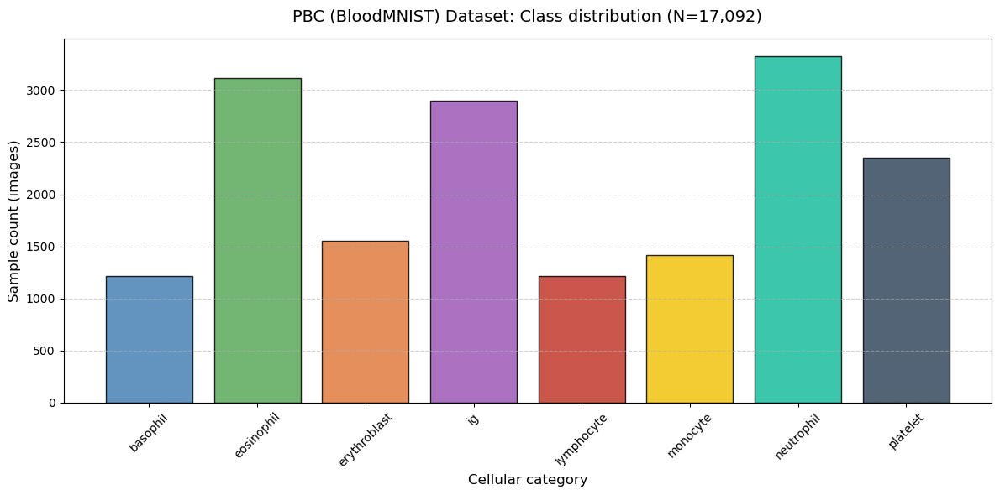


Exploratory Data Analysis (EDA) complete.
NOTE: The dataset has a moderate imbalance.


In [7]:
import os
import matplotlib.pyplot as plt

base_dir = '/content/pbc_dataset/full_dataset'
VALID_EXTENSIONS = ('.jpg', '.jpeg', '.png', '.bmp', '.tiff', '.JPG', '.JPEG', '.PNG', '.BMP', '.TIFF')

# Official nomenclature of the 8 classes of the PBC dataset
categories = ['basophil', 'eosinophil', 'erythroblast', 'ig', 'lymphocyte', 'monocyte', 'neutrophil', 'platelet']

data_summary = []
for category in sorted(os.listdir(base_dir)):
    path = os.path.join(base_dir, category)
    if os.path.isdir(path) and category.lower() in categories:
        n = len([f for f in os.listdir(path) if f.lower().endswith(VALID_EXTENSIONS)])
        data_summary.append((category.lower(), n))

total_n = sum(count for _, count in data_summary)
print(f'✓ Población total (N): {total_n}')
print(f'\nMatriz de Distribución de Clases:')
print(f"  {'Clase':<15} {'N':>6} {'%':>7}")
print(f"  {'-'*40}")
for code, n in data_summary:
    pct = (n / total_n) * 100
    bar_visual = '█' * int(pct / 2)
    print(f'  {code:<15} {n:>6} {pct:>6.1f}%  {bar_visual}')

plt.figure(figsize=(12, 6))
codes  = [item[0] for item in data_summary]
counts = [item[1] for item in data_summary]
# 8-color palette for different cell types
colors = ['#4682B4', '#5BA85A', '#E07B3F', '#9B59B6', '#C0392B', '#F1C40F', '#1ABC9C', '#34495E']

plt.bar(codes, counts, color=colors, edgecolor='black', alpha=0.85)
plt.title(f'PBC (BloodMNIST) Dataset: Class distribution (N={total_n:,})', fontsize=14, pad=15)
plt.xlabel('Cellular category', fontsize=12)
plt.ylabel('Sample count (images)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.xticks(rotation=45) # Added for readability of long names
plt.tight_layout()
plt.show()

print('\nExploratory Data Analysis (EDA) complete.')
print('NOTE: The dataset has a moderate imbalance.')


CLASS WEIGHTING STRATEGY (CrossEntropyLoss)
  Formula  : total_N / (n_classes × class_N)
  Total N  : 17,092
  N classes : 8

  Class                 N          Weight
  ---------------------------------------------
  basophil          1,218          1.7541
  eosinophil        3,117          0.6854
  erythroblast      1,551          1.3775
  ig                2,895          0.7380
  lymphocyte        1,214          1.7599
  monocyte          1,420          1.5046
  neutrophil        3,329          0.6418
  platelet          2,348          0.9099

✓ WeightedRandomSampler configured.
  Samples by epoch: 19,424
  Minority class (lymphocyte) view: ~2.0x by epoch


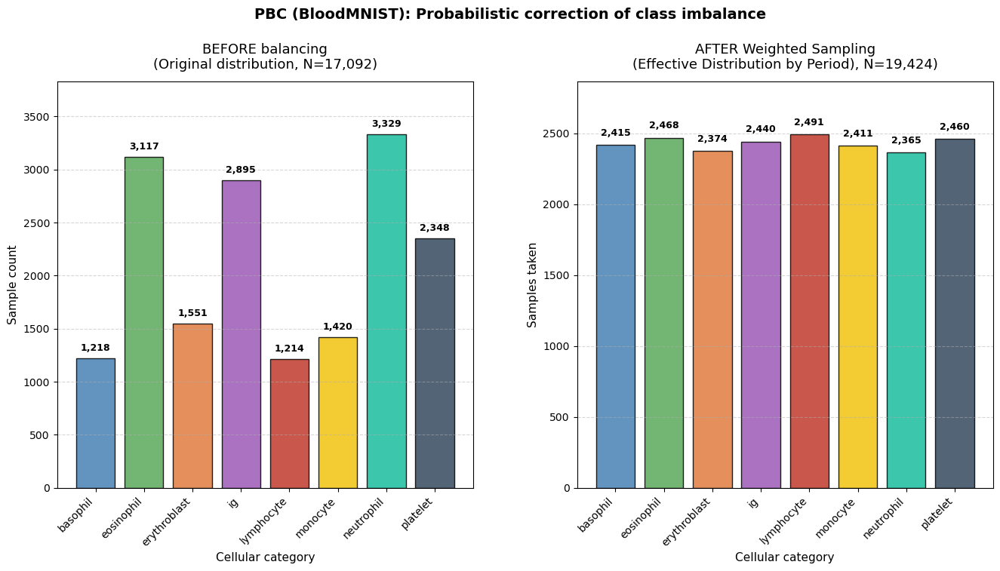


 Balancing strategy configured.
 → class_weights : Using standard CrossEntropyLoss
 → sample_weights : used in WeightedRandomSampler
 → 100% probabilistic operation; no original image was duplicated on disk.


In [8]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from collections import Counter

base_dir = '/content/pbc_dataset/full_dataset'
VALID_EXTENSIONS = ('.jpg', '.jpeg', '.png', '.bmp', '.tiff', '.JPG', '.JPEG', '.PNG', '.BMP', '.TIFF')

# Ensure order and accurate nomenclature
categories = sorted([
    d for d in os.listdir(base_dir)
    if os.path.isdir(os.path.join(base_dir, d))
])

class_counts = {}
for category in categories:
    path = os.path.join(base_dir, category)
    n = len([f for f in os.listdir(path) if f.lower().endswith(VALID_EXTENSIONS)])
    class_counts[category] = n

total_n   = sum(class_counts.values())
n_classes = len(categories)

# ─── 1. CLASS WEIGHTS FOR LOSS FUNCTION ───
class_weights = {
    cls: total_n / (n_classes * count)
    for cls, count in class_counts.items()
}

print("=" * 60)
print("CLASS WEIGHTING STRATEGY (CrossEntropyLoss)")
print("=" * 60)
print(f"  Formula  : total_N / (n_classes × class_N)")
print(f"  Total N  : {total_n:,}")
print(f"  N classes : {n_classes}")
print(f"\n  {'Class':<15} {'N':>7} {'Weight':>15}")
print(f"  {'-'*45}")
for cls in categories:
    print(f"  {cls:<15} {class_counts[cls]:>7,} {class_weights[cls]:>15.4f}")

# ─── 2. WEIGHTED RANDOM SAMPLER ───
all_labels = []
for idx, cls in enumerate(categories):
    all_labels.extend([idx] * class_counts[cls])

sample_weights = [
    class_weights[categories[label]] for label in all_labels
]

# Adjustment for 8 classes: ensuring sufficient exposure of the minority class
min_class_count = min(class_counts.values())
min_class_name = [k for k, v in class_counts.items() if v == min_class_count][0]

num_samples = int(min_class_count) * n_classes * 2

print(f"\n✓ WeightedRandomSampler configured.")
print(f"  Samples by epoch: {num_samples:,}")
print(f"  Minority class ({min_class_name}) view: ~{num_samples // n_classes / min_class_count:.1f}x by epoch")

np.random.seed(2026)
probs            = np.array(sample_weights) / np.array(sample_weights).sum()
sampled_epoch  = np.random.choice(len(all_labels), size=num_samples, replace=True, p=probs)
sampled_counts = Counter([categories[all_labels[i]] for i in sampled_epoch])

# ─── 4. VISUALIZATION: BEFORE vs AFTER ───
fig = plt.figure(figsize=(16, 7))
gs  = gridspec.GridSpec(1, 2, wspace=0.25)
# 8-color palette
colors = ['#4682B4', '#5BA85A', '#E07B3F', '#9B59B6', '#C0392B', '#F1C40F', '#1ABC9C', '#34495E']

# Chart 1: Before Balancing
ax1 = fig.add_subplot(gs[0])
vals_before = [class_counts[c] for c in categories]
bars1 = ax1.bar(categories, vals_before, color=colors, edgecolor='black', alpha=0.85)
ax1.set_title(f"BEFORE balancing\n(Original distribution, N={total_n:,})", fontsize=13, pad=12)
ax1.set_xlabel("Cellular category", fontsize=11)
ax1.set_ylabel("Sample count", fontsize=11)
ax1.set_xticks(range(len(categories)))
ax1.set_xticklabels(categories, rotation=45, ha='right')
ax1.grid(axis='y', linestyle='--', alpha=0.5)

# Avoid text overlap by adjusting the Y boundary
ax1.set_ylim(0, max(vals_before) * 1.15)
for bar, val in zip(bars1, vals_before):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50,
             f'{val:,}', ha='center', va='bottom', fontsize=9, fontweight='bold')

# Chart 2: After stochastic balancing
ax2 = fig.add_subplot(gs[1])
vals_after = [sampled_counts[c] for c in categories]
bars2 = ax2.bar(categories, vals_after, color=colors, edgecolor='black', alpha=0.85)
ax2.set_title(f"AFTER Weighted Sampling\n(Effective Distribution by Period), N={num_samples:,})", fontsize=13, pad=12)
ax2.set_xlabel("Cellular category", fontsize=11)
ax2.set_ylabel("Samples taken", fontsize=11)
ax2.set_xticks(range(len(categories)))
ax2.set_xticklabels(categories, rotation=45, ha='right')
ax2.grid(axis='y', linestyle='--', alpha=0.5)

ax2.set_ylim(0, max(vals_after) * 1.15)
for bar, val in zip(bars2, vals_after):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50,
             f'{val:,}', ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.suptitle("PBC (BloodMNIST): Probabilistic correction of class imbalance",
             fontsize=14, fontweight='bold', y=1.02)
plt.show()

print("\n Balancing strategy configured.")
print(" → class_weights : Using standard CrossEntropyLoss")
print(" → sample_weights : used in WeightedRandomSampler")
print(" → 100% probabilistic operation; no original image was duplicated on disk.")


In [9]:
# =============================================================
# MODEL ARCHITECTURE DEFINITION (RESNET18)
# =============================================================
import torch.nn as nn
from torchvision.models import resnet18

class ResNet18(nn.Module):
    """
    ResNet18 architecture initialized with random weights (no pre-training).
    """
    def __init__(self, num_classes=8):
        super(ResNet18, self).__init__()
        # Initializing without pre-trained weights
        self.model = resnet18(weights=None)

        # Adjusting the final fully connected layer
        in_features = self.model.fc.in_features
        self.model.fc = nn.Sequential(
            nn.Dropout(p=0.5), # Dropout
            nn.Linear(in_features, num_classes)
        )

    def forward(self, x):
        return self.model(x)


In [10]:
# =============================================================
# PROPOSED OPTIMIZER
# =============================================================
import torch
from torch.optim import Optimizer


class AdaHarmon(Optimizer):
    r"""
    AdaHarmon: Adaptive Harmonic Optimizer

    Algorithm:
    ----------
    Let g_t be the gradient at step t.

    1. Sign consistency tracker:
       s_t = β_s · s_{t-1} + (1 - β_s) · sign(g_t)

    2. Adaptive momentum:
       β₁^(t) = β₁ · (1 + λ|s_t|) / (1 + λ)
       μ_t    = μ_{t-1} · β₁^(t)           ← exact accumulated product

    3. First moment (gradient EMA):
       m_t = β₁^(t) · m_{t-1} + (1 - β₁^(t)) · g_t
       m̂_t = m_t / (1 - μ_t)               ← exact bias correction

    4. Second moment (L2 norm):
       v_t = β₂ · v_{t-1} + (1 - β₂) · g_t²
       v̂_t = v_t / (1 - β₂^t)

    5. L∞ norm with soft decay:
       δ_t = 1 + soft_decay · 𝟙[|g_t| < τ · u_{t-1}]
       u_t = max(β₂^{δ_t} · u_{t-1}, |g_t|)

    6. Hybrid denominator (harmonic mean of L2 and L∞):
       h̃_t = 2·√v̂_t · u_t / (√v̂_t + u_t + ε₁)

    7. Parameter update:
       θ_t = θ_{t-1} - α · m̂_t / (h̃_t + ε₂)

    Arguments:
    ----------
    params      : model parameters
    lr          : learning rate α (default: 1e-3)
    betas       : (β₁, β₂, β_s) EMA coefficients (default: 0.9, 0.999, 0.9)
    eps         : (ε₁, ε₂) inner and outer epsilons (default: 1e-8, 1e-6)
    lambda_s    : λ scale for adaptive momentum (default: 1.0)
    soft_decay  : extra decay when gradient < threshold (default: 0.5)
    tau         : relative threshold for u_t decay (default: 0.1)
    amsgrad     : use AMSGrad variant for second moment (default: False)
    """

    def __init__(
        self,
        params,
        lr: float = 1e-3,
        betas: tuple = (0.9, 0.999, 0.9),
        eps: tuple = (1e-8, 1e-6),
        lambda_s: float = 1.0,
        soft_decay: float = 0.5,
        tau: float = 0.1,
        amsgrad: bool = False,
    ):
        if lr < 0.0:
            raise ValueError(f"Invalid lr: {lr}")
        if not (0.0 <= betas[0] < 1.0):
            raise ValueError(f"Invalid β₁: {betas[0]}")
        if not (0.0 <= betas[1] < 1.0):
            raise ValueError(f"Invalid β₂: {betas[1]}")
        if not (0.0 <= betas[2] < 1.0):
            raise ValueError(f"Invalid β_s: {betas[2]}")
        if eps[0] <= 0 or eps[1] <= 0:
            raise ValueError(f"eps must be positive: {eps}")

        defaults = dict(
            lr=lr,
            betas=betas,
            eps=eps,
            lambda_s=lambda_s,
            soft_decay=soft_decay,
            tau=tau,
            amsgrad=amsgrad,
        )
        super(AdaHarmon, self).__init__(params, defaults)

    def __setstate__(self, state):
        super(AdaHarmon, self).__setstate__(state)
        for group in self.param_groups:
            group.setdefault("amsgrad", False)

    @torch.no_grad()
    def step(self, closure=None):
        """Performs a single optimization step."""
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()

        for group in self.param_groups:
            beta1, beta2, beta_s = group["betas"]
            eps1, eps2 = group["eps"]
            lr = group["lr"]
            lambda_s = group["lambda_s"]
            soft_decay = group["soft_decay"]
            tau = group["tau"]
            amsgrad = group["amsgrad"]

            for p in group["params"]:
                if p.grad is None:
                    continue

                grad = p.grad
                if grad.is_sparse:
                    raise RuntimeError(
                        "AdaHarmon does not support sparse gradients."
                    )

                state = self.state[p]

                # ── State initialization ───────────────────────────────────
                if len(state) == 0:
                    state["step"] = 0
                    state["m"] = torch.zeros_like(p)   # first moment
                    state["v"] = torch.zeros_like(p)   # second moment (L2)
                    state["u"] = torch.zeros_like(p)   # L∞ norm
                    state["s"] = torch.zeros_like(p)   # sign consistency tracker
                    state["mu"] = torch.ones_like(p)   # accumulated product μ_t
                    if amsgrad:
                        state["v_max"] = torch.zeros_like(p)

                state["step"] += 1
                t = state["step"]
                m, v, u, s, mu = (
                    state["m"], state["v"], state["u"],
                    state["s"], state["mu"]
                )

                # ── Step 1: Sign consistency tracker ──────────────────────
                # s_t = β_s · s_{t-1} + (1 - β_s) · sign(g_t)
                s.mul_(beta_s).add_(torch.sign(grad), alpha=(1.0 - beta_s))

                # ── Step 2: Adaptive momentum per parameter ────────────────
                # β₁^(t) = β₁ · (1 + λ|s_t|) / (1 + λ)
                beta1_t = beta1 * (1.0 + lambda_s * s.abs()) / (1.0 + lambda_s)
                beta1_t.clamp_(0.0, 1.0 - 1e-9)

                # μ_t = μ_{t-1} · β₁^(t)  (exact accumulated product)
                mu.mul_(beta1_t)

                # ── Step 3: First moment with exact bias correction ────────
                # m_t = β₁^(t) · m_{t-1} + (1 - β₁^(t)) · g_t
                m.mul_(beta1_t).addcmul_(
                    (1.0 - beta1_t), grad
                )
                # m̂_t = m_t / (1 - μ_t)
                bias_correction_m = 1.0 - mu
                bias_correction_m.clamp_(min=1e-12)  # avoid div/0 at step 1
                m_hat = m / bias_correction_m

                # ── Step 4: Second moment (L2 norm) ───────────────────────
                # v_t = β₂ · v_{t-1} + (1 - β₂) · g_t²
                v.mul_(beta2).addcmul_(grad, grad, value=(1.0 - beta2))

                if amsgrad:
                    v_max = state["v_max"]
                    torch.maximum(v_max, v, out=v_max)
                    v_eff = v_max
                else:
                    v_eff = v

                # v̂_t = v_t / (1 - β₂^t)
                bias_correction_v = 1.0 - beta2 ** t
                v_hat = v_eff / bias_correction_v

                # ── Step 5: L∞ norm with soft decay ───────────────────────
                # δ_t: extra decay when |g_t| < τ · u_{t-1}
                # Prevents u_t from freezing at historical peaks
                grad_abs = grad.abs()
                plateau_mask = (grad_abs < tau * u).float()
                # β₂^δ_t where δ_t = 1 + soft_decay · 𝟙[plateau]
                beta2_eff = beta2 ** (1.0 + soft_decay * plateau_mask)
                # u_t = max(β₂^{δ_t} · u_{t-1}, |g_t|)
                torch.maximum(beta2_eff * u, grad_abs, out=u)

                # ── Step 6: Hybrid denominator (harmonic mean) ─────────────
                # h̃_t = 2·√v̂_t · u_t / (√v̂_t + u_t + ε₁)
                sqrt_v_hat = v_hat.sqrt()
                numerator = 2.0 * sqrt_v_hat * u
                denominator_inner = sqrt_v_hat + u + eps1
                h_tilde = numerator / denominator_inner

                # ── Step 7: Parameter update ──────────────────────────────
                # θ_t = θ_{t-1} - α · m̂_t / (h̃_t + ε₂)
                p.addcdiv_(m_hat, h_tilde + eps2, value=-lr)

        return loss

In [11]:
# =============================================================
# OPTIMIZER COMPLEXITY AND EFFICIENCY ANALYSIS
# =============================================================
import pynvml
import warnings

class OptimizerComplexity:
    """
    Analyzes the computational overhead and energy efficiency of the optimizers.
    Metrics based on Floating Point Operations (FLOPs) per parameter.
    """
    def __init__(self, optimizer_name, num_params):
        self.optimizer_name = optimizer_name
        self.num_params     = num_params
        self.ops_per_param  = self._estimate_flops_per_param()

    def _estimate_flops_per_param(self):
        """
        FLOPs per parameter for the optimizer step alone.
        Convention follows Sun et al. (2020), AdaBelief, Appendix A.
        Values match Table 5 of the manuscript.
        """
        if self.optimizer_name == "SGD":
            # v = beta*v + g; theta = theta - lr*v
            return 4
        elif self.optimizer_name == "RMSprop":
            # v = beta*v + (1-beta)*g^2; theta = theta - lr*g/(sqrt(v)+eps)
            return 9
        elif self.optimizer_name == "Adam":
            # m, v updates + bias-corrected parameter step
            return 14
        elif self.optimizer_name == "AdamW":
            # Adam + decoupled weight decay (theta = theta - lr*wd*theta)
            return 16
        elif self.optimizer_name == "RAdam":
            # Adam + variance rectification term
            return 15
        elif self.optimizer_name == "AdaHarmon":
            # sign EMA + adaptive momentum + soft-decay L_inf + harmonic mean
            return 37
        elif self.optimizer_name == "AdaBelief":
            # m update, s update with (g - m)^2, bias corrections, update step
            return 16
        elif self.optimizer_name == "Lion":
            # c_t update, sign step, decoupled wd, m update
            return 7
        elif self.optimizer_name == "AMSGrad":
            # Adam + max(v_max, v) tracking
            return 15
        elif self.optimizer_name == "Adamax":
            # m update + infinity norm update + update step
            return 11
        else:
            warnings.warn(f"Optimizer '{self.optimizer_name}' not standardized. Returning 0.")
            return 0

    def get_flops_per_param(self):
        return self.ops_per_param

    def get_total_flops(self):
        """Total theoretical FLOPs for one full update of the model."""
        return self.ops_per_param * self.num_params

    def get_estimated_energy_joules(self, total_time_s):
        """
        Estimates energy consumption in Joules using NVML power metrics.
        Fallback to 250W average TDP for standard research GPUs.
        """
        try:
            pynvml.nvmlInit()
            handle = pynvml.nvmlDeviceGetHandleByIndex(0)
            power_mw = pynvml.nvmlDeviceGetPowerUsage(handle)
            pynvml.nvmlShutdown()
            return (power_mw / 1000.0) * total_time_s
        except Exception:
            return 250.0 * total_time_s

In [12]:
import os
import time
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import numpy as np
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import label_binarize


def count_parameters(model):
    """Calculate the total number of trainable parameters in the architecture."""
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def train_and_evaluate_model(model, optimizer_name, hparams,
                             train_loader, train_eval_loader,
                             val_loader, test_loader,
                             train_dataset, val_dataset, test_dataset,
                             NUM_EPOCHS, NUM_CLASSES, device):

    model.to(device)

    # ── OPTIMIZER INITIALIZATION ──────────────────────────────────────────────
    if optimizer_name == "Adam":
        optimizer = optim.Adam(
            model.parameters(),
            lr=hparams['lr'],
            betas=hparams.get('betas', (0.9, 0.999)),
            eps=hparams.get('eps', 1e-8)
        )
    elif optimizer_name == "AdamW":
        optimizer = optim.AdamW(
            model.parameters(),
            lr=hparams['lr'],
            betas=hparams.get('betas', (0.9, 0.999)),
            eps=hparams.get('eps', 1e-8),
            weight_decay=hparams.get('weight_decay', 0.01)
        )
    elif optimizer_name == "RAdam":
        optimizer = optim.RAdam(
            model.parameters(),
            lr=hparams['lr'],
            betas=hparams.get('betas', (0.9, 0.999)),
            eps=hparams.get('eps', 1e-8)
        )
    elif optimizer_name == "AdaHarmon":
        optimizer = AdaHarmon(
            model.parameters(),
            lr=hparams['lr'],
            betas=hparams.get('betas', (0.9, 0.999, 0.9)),
            eps=hparams.get('eps', (1e-8, 1e-6)),
            lambda_s=hparams.get('lambda_s', 1.0),
            soft_decay=hparams.get('soft_decay', 0.5),
            tau=hparams.get('tau', 0.1),
            amsgrad=hparams.get('amsgrad', False)
        )
    elif optimizer_name == "RMSprop":
        optimizer = optim.RMSprop(
            model.parameters(),
            lr=hparams['lr'],
            alpha=hparams.get('alpha', 0.99),
            eps=hparams.get('eps', 1e-8)
        )
    elif optimizer_name == "SGD":
        optimizer = optim.SGD(
            model.parameters(),
            lr=hparams['lr'],
            momentum=hparams.get('momentum', 0.9),
            weight_decay=hparams.get('weight_decay', 0)
        )
    elif optimizer_name == "AdaBelief":
        from adabelief_pytorch import AdaBelief
        optimizer = AdaBelief(
            model.parameters(),
            lr=hparams['lr'],
            betas=hparams.get('betas', (0.9, 0.999)),
            eps=hparams.get('eps', 1e-8),
            weight_decay=hparams.get('weight_decay', 0),
            weight_decouple=hparams.get('weight_decouple', False),
            rectify=hparams.get('rectify', False),
            print_change_log=False
        )
    elif optimizer_name == "Lion":
        from lion_pytorch import Lion
        optimizer = Lion(
            model.parameters(),
            lr=hparams['lr'],
            betas=hparams.get('betas', (0.9, 0.99)),
            weight_decay=hparams.get('weight_decay', 0.1)
        )
    elif optimizer_name == "AMSGrad":
        optimizer = optim.Adam(
            model.parameters(),
            lr=hparams['lr'],
            betas=hparams.get('betas', (0.9, 0.999)),
            eps=hparams.get('eps', 1e-8),
            weight_decay=hparams.get('weight_decay', 0),
            amsgrad=True
        )
    elif optimizer_name == "Adamax":
        optimizer = optim.Adamax(
            model.parameters(),
            lr=hparams['lr'],
            betas=hparams.get('betas', (0.9, 0.999)),
            eps=hparams.get('eps', 1e-8),
            weight_decay=hparams.get('weight_decay', 0)
        )
    else:
        raise ValueError(f"Unknown optimizer: {optimizer_name}")

    criterion = nn.CrossEntropyLoss()

    # ── HISTORIAL ─────────────────────────────────────────────────────────────
    history = {
        'train_loss': [], 'val_loss': [],
        'train_acc':  [], 'val_acc':  [],
        'val_auc':    [], 'epoch_times': []
    }

    best_val_acc  = 0.0
    best_epoch    = 0
    start_time    = time.time()


    for epoch in range(NUM_EPOCHS):
        epoch_start = time.time()

        # ── Training phase ────────────────────────────────────────────────────
        model.train()
        for inputs, batch_labels in train_loader:
            inputs, batch_labels = inputs.to(device), batch_labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, batch_labels)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

        # ── Evaluation phase ──────────────────────────────────────────────────
        model.eval()

        metrics = {
            'trn': {'loss': 0.0, 'corr': 0, 'tot': 0},
            'val': {'loss': 0.0, 'corr': 0, 'tot': 0, 'scores': [], 'labels': []}
        }

        with torch.no_grad():
            for inputs, batch_labels in train_eval_loader:
                inputs, batch_labels = inputs.to(device), batch_labels.to(device)
                outputs = model(inputs)
                loss    = criterion(outputs, batch_labels)
                metrics['trn']['loss'] += loss.item() * inputs.size(0)
                _, predicted = torch.max(outputs.data, 1)
                metrics['trn']['tot']  += batch_labels.size(0)
                metrics['trn']['corr'] += (predicted == batch_labels).sum().item()

            for inputs, batch_labels in val_loader:
                inputs, batch_labels = inputs.to(device), batch_labels.to(device)
                outputs = model(inputs)
                loss    = criterion(outputs, batch_labels)
                metrics['val']['loss'] += loss.item() * inputs.size(0)
                _, predicted = torch.max(outputs.data, 1)
                metrics['val']['tot']  += batch_labels.size(0)
                metrics['val']['corr'] += (predicted == batch_labels).sum().item()
                metrics['val']['labels'].extend(batch_labels.cpu().numpy())
                metrics['val']['scores'].append(F.softmax(outputs, dim=1).cpu().numpy())

        epoch_trn_loss = metrics['trn']['loss'] / len(train_dataset)
        epoch_trn_acc  = metrics['trn']['corr'] / metrics['trn']['tot']
        epoch_val_loss = metrics['val']['loss'] / len(val_dataset)
        epoch_val_acc  = metrics['val']['corr'] / metrics['val']['tot']

        val_scores_concat = np.vstack(metrics['val']['scores'])
        y_bin = label_binarize(metrics['val']['labels'], classes=list(range(NUM_CLASSES)))

        try:
            epoch_val_auc = roc_auc_score(
                y_bin, val_scores_concat, average='macro', multi_class='ovr'
            )
        except Exception:
            epoch_val_auc = 0.0

        epoch_time = time.time() - epoch_start

        history['train_loss'].append(epoch_trn_loss)
        history['train_acc'].append(epoch_trn_acc)
        history['val_loss'].append(epoch_val_loss)
        history['val_acc'].append(epoch_val_acc)
        history['val_auc'].append(epoch_val_auc)
        history['epoch_times'].append(epoch_time)

        if epoch_val_acc > best_val_acc:
            best_val_acc = epoch_val_acc
            best_epoch   = epoch + 1

        print(
            f"Epoch {epoch+1}/{NUM_EPOCHS} -> "
            f"Trn Loss: {epoch_trn_loss:.4f}, Trn Acc: {epoch_trn_acc:.4f} | "
            f"Val Loss: {epoch_val_loss:.4f}, Val Acc: {epoch_val_acc:.4f}, "
            f"Val AUC: {epoch_val_auc:.4f}"
            + (" ✓ best" if epoch + 1 == best_epoch else "")
        )

    torch.cuda.empty_cache()

    # ── Test evaluation ───────────────────────────────────────────────────────
    model.eval()

    y_true, y_scores_list, y_pred = [], [], []
    test_loss, correct_test = 0.0, 0

    with torch.no_grad():
        for inputs, batch_labels in test_loader:
            inputs, batch_labels = inputs.to(device), batch_labels.to(device)
            outputs = model(inputs)
            loss    = criterion(outputs, batch_labels)
            test_loss     += loss.item() * inputs.size(0)
            _, predicted   = torch.max(outputs.data, 1)
            correct_test  += (predicted == batch_labels).sum().item()
            y_true.extend(batch_labels.cpu().numpy())
            y_scores_list.append(F.softmax(outputs, dim=1).cpu().numpy())
            y_pred.extend(predicted.cpu().numpy())

    from sklearn.metrics import accuracy_score, f1_score, recall_score
    y_scores_np = np.vstack(y_scores_list)
    y_bin_test  = label_binarize(y_true, classes=list(range(NUM_CLASSES)))
    try:
        test_auc = roc_auc_score(
            y_bin_test, y_scores_np, average='macro', multi_class='ovr'
        )
    except Exception:
        test_auc = 0.0

    test_accuracy = accuracy_score(y_true, y_pred)
    test_f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)
    test_recall = recall_score(y_true, y_pred, average="macro", zero_division=0)

    final_results = {
        "optimizer":       optimizer_name,
        "best_epoch":      best_epoch,
        "best_val_acc":    best_val_acc,
        "test_loss":       test_loss / len(test_dataset),
        "test_accuracy":   test_accuracy,
        "test_auc":        test_auc,
        "f1_score":        test_f1,
        "recall":          test_recall,
        "y_true":          y_true,
        "y_pred":          y_pred,
        "y_scores":        y_scores_np,
        "training_time":   time.time() - start_time,
        "params":          count_parameters(model)
    }

    print(
        f"  Test  -> Acc: {final_results['test_accuracy']:.4f} | "
        f"Loss: {final_results['test_loss']:.4f} | "
        f"AUC: {test_auc:.4f}"
    )

    return final_results, history


In [13]:
import os
import torch
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, Dataset, random_split, WeightedRandomSampler
from torchvision.datasets import ImageFolder
import numpy as np

# Standard normalization for ImageNet (applicable to training from scratch)
normalize = transforms.Normalize(
    mean=[0.485, 0.456, 0.406],
    std=[0.229, 0.224, 0.225]
)

# Data augmentation optimized for 64x64 and PBC
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=30),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1), scale=(0.8, 1.2)),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2, hue=0.05),
    transforms.RandomResizedCrop(size=IMG_SIZE, scale=(0.7, 1.0)),
    transforms.ToTensor(),
    normalize,
])

test_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    normalize
])

class PBCDataset(Dataset):
    """
    Wrapper for handling subsets with specific transformations.
    """
    def __init__(self, subset, transform=None):
        self.subset    = subset
        self.transform = transform

    def __getitem__(self, index):
        x, y = self.subset[index]
        if self.transform:
            x = self.transform(x)
        return x, y

    def __len__(self):
        return len(self.subset)

# PBC dataset route
data_path    = '/content/pbc_dataset/full_dataset'
full_dataset = ImageFolder(root=data_path)

print(f'Clases detectadas ({NUM_CLASSES}): {full_dataset.classes}')

# Standard split: 70% training, 15% validation, 15% testing
train_size = int(0.70 * len(full_dataset))
val_size   = int(0.15 * len(full_dataset))
test_size  = len(full_dataset) - train_size - val_size

train_sub, val_sub, test_sub = random_split(
    full_dataset, [train_size, val_size, test_size],
    generator=torch.Generator().manual_seed(SEED)
)

train_dataset      = PBCDataset(train_sub, transform=train_transform)
train_eval_dataset = PBCDataset(train_sub, transform=test_transform)
val_dataset        = PBCDataset(val_sub,   transform=test_transform)
test_dataset       = PBCDataset(test_sub,  transform=test_transform)

# ─── WEIGHTED RANDOM SAMPLER ───
train_labels    = [full_dataset.targets[i] for i in train_sub.indices]
class_counts_s  = np.bincount(train_labels, minlength=NUM_CLASSES)
class_weights_s = 1.0 / (class_counts_s + 1e-8)
sample_weights  = [class_weights_s[label] for label in train_labels]

# Definition of samples by epoch for PBC (8 classes)
num_samples = int(class_counts_s.min()) * NUM_CLASSES * 2

print(f"\n  Samples by epoch (sampler): {num_samples:,}")
print(f"  Minority class in training: {class_counts_s.min()} images")
print(f"  Exposition ~{num_samples // NUM_CLASSES / class_counts_s.min():.1f}x by epoch")

sampler = WeightedRandomSampler(
    weights     = sample_weights,
    num_samples = num_samples,
    replacement = True
)

# Configuring DataLoaders for high performance
train_loader      = DataLoader(train_dataset,      batch_size=BATCH_SIZE, sampler=sampler,  num_workers=2, pin_memory=True)
train_eval_loader = DataLoader(train_eval_dataset, batch_size=BATCH_SIZE, shuffle=False,    num_workers=2, pin_memory=True)
val_loader        = DataLoader(val_dataset,        batch_size=BATCH_SIZE, shuffle=False,    num_workers=2, pin_memory=True)
test_loader       = DataLoader(test_dataset,       batch_size=BATCH_SIZE, shuffle=False,    num_workers=2, pin_memory=True)

print(f'\n DataLoaders configured for PBC.')
print(f'  Train (total) : {len(train_dataset):,}')
print(f'  Val           : {len(val_dataset):,}')
print(f'  Test          : {len(test_dataset):,}')
print(f'  Effective samples/epoch: {num_samples:,}')


Clases detectadas (8): ['basophil', 'eosinophil', 'erythroblast', 'ig', 'lymphocyte', 'monocyte', 'neutrophil', 'platelet']

  Samples by epoch (sampler): 13,632
  Minority class in training: 852 images
  Exposition ~2.0x by epoch

 DataLoaders configured for PBC.
  Train (total) : 11,964
  Val           : 2,563
  Test          : 2,565
  Effective samples/epoch: 13,632


In [14]:
# =============================================================
# OPTIMIZER EXECUTION LOOP - PBC (BLOODMNIST)
# =============================================================
import os
import torch
import random
import numpy as np

# 1. Directory configuration

OPTIMIZERS_TO_RUN = ["Adam", "AdamW", "RAdam", "AdaHarmon", "RMSprop", "SGD", "AdaBelief", "Lion", "AMSGrad", "Adamax"]

all_results   = {}
all_histories = {}

# 2. Execution loop
for opt_name in OPTIMIZERS_TO_RUN:
    torch.manual_seed(2026)
    torch.cuda.manual_seed_all(2026)
    np.random.seed(2026)
    random.seed(2026)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    print(f"\n" + "="*60)
    print(f"  EXECUTING EXPERIMENT: {opt_name}")
    print("="*60)

    model = ResNet18(num_classes=NUM_CLASSES)

    results, history = train_and_evaluate_model(
        model             = model,
        optimizer_name    = opt_name,
        hparams           = HYPERPARAMS[opt_name],
        train_loader      = train_loader,
        train_eval_loader = train_eval_loader,
        val_loader        = val_loader,
        test_loader       = test_loader,
        train_dataset     = train_dataset,
        val_dataset       = val_dataset,
        test_dataset      = test_dataset,
        NUM_EPOCHS        = NUM_EPOCHS,
        NUM_CLASSES       = NUM_CLASSES,
        device            = torch.device("cuda" if torch.cuda.is_available() else "cpu"),
    )


    all_results[opt_name]   = results
    all_histories[opt_name] = history

# 3. Final comparative summary
print("\n" + "="*110)
print(f"{'FINAL COMPARATIVE PERFORMANCE SUMMARY — PBC (BLOODMNIST)':^110}")
print("="*110)
print(f"{'Optimizer':<20} | {'Trn Acc (%)':<11} | {'Trn Loss':<10} | "
      f"{'Val Acc (%)':<11} | {'Val Loss':<10} | {'Test Acc (%)':<12} | {'Test Loss':<10}")
print("-" * 110)

sorted_results = sorted(all_results.items(),
                        key=lambda x: x[1]['test_accuracy'], reverse=True)

for opt_name, res in sorted_results:
    h        = all_histories[opt_name]
    trn_acc  = h['train_acc'][-1]  * 100
    trn_loss = h['train_loss'][-1]
    val_acc  = h['val_acc'][-1]    * 100
    val_loss = h['val_loss'][-1]
    tst_acc  = res['test_accuracy'] * 100
    tst_loss = res['test_loss']
    top_indicator = " [TOP]" if opt_name == sorted_results[0][0] else ""

    print(f"{opt_name:<20} | {trn_acc:<11.2f} | {trn_loss:<10.4f} | "
          f"{val_acc:<11.2f} | {val_loss:<10.4f} | {tst_acc:<12.2f} | {tst_loss:<10.4f}{top_indicator}")

print("-" * 110)




  EXECUTING EXPERIMENT: Adam
Epoch 1/80 -> Trn Loss: 1.7358, Trn Acc: 0.3970 | Val Loss: 1.7728, Val Acc: 0.3780, Val AUC: 0.8725 ✓ best
Epoch 2/80 -> Trn Loss: 1.3365, Trn Acc: 0.5851 | Val Loss: 1.3323, Val Acc: 0.5920, Val AUC: 0.9497 ✓ best
Epoch 3/80 -> Trn Loss: 1.1306, Trn Acc: 0.6803 | Val Loss: 1.1383, Val Acc: 0.6861, Val AUC: 0.9643 ✓ best
Epoch 4/80 -> Trn Loss: 1.5675, Trn Acc: 0.6720 | Val Loss: 1.5768, Val Acc: 0.6731, Val AUC: 0.9396
Epoch 5/80 -> Trn Loss: 0.8735, Trn Acc: 0.7297 | Val Loss: 0.8743, Val Acc: 0.7348, Val AUC: 0.9736 ✓ best
Epoch 6/80 -> Trn Loss: 0.5720, Trn Acc: 0.8114 | Val Loss: 0.6088, Val Acc: 0.8116, Val AUC: 0.9723 ✓ best
Epoch 7/80 -> Trn Loss: 0.6826, Trn Acc: 0.7782 | Val Loss: 0.7201, Val Acc: 0.7714, Val AUC: 0.9653
Epoch 8/80 -> Trn Loss: 0.4584, Trn Acc: 0.8484 | Val Loss: 0.4563, Val Acc: 0.8601, Val AUC: 0.9923 ✓ best
Epoch 9/80 -> Trn Loss: 0.5756, Trn Acc: 0.8048 | Val Loss: 0.6012, Val Acc: 0.7945, Val AUC: 0.9711
Epoch 10/80 -> Trn




  EXECUTING EXPERIMENT: AdamW
Epoch 1/80 -> Trn Loss: 1.7464, Trn Acc: 0.3799 | Val Loss: 1.6198, Val Acc: 0.4395, Val AUC: 0.8730 ✓ best
Epoch 2/80 -> Trn Loss: 1.5383, Trn Acc: 0.4795 | Val Loss: 1.4073, Val Acc: 0.5626, Val AUC: 0.9344 ✓ best
Epoch 3/80 -> Trn Loss: 1.2310, Trn Acc: 0.6232 | Val Loss: 1.3357, Val Acc: 0.6374, Val AUC: 0.9623 ✓ best
Epoch 4/80 -> Trn Loss: 1.3388, Trn Acc: 0.6720 | Val Loss: 1.2061, Val Acc: 0.6963, Val AUC: 0.9470 ✓ best
Epoch 5/80 -> Trn Loss: 1.2113, Trn Acc: 0.6995 | Val Loss: 1.0118, Val Acc: 0.7315, Val AUC: 0.9767 ✓ best
Epoch 6/80 -> Trn Loss: 0.7411, Trn Acc: 0.7734 | Val Loss: 0.7361, Val Acc: 0.7753, Val AUC: 0.9868 ✓ best
Epoch 7/80 -> Trn Loss: 0.6556, Trn Acc: 0.8054 | Val Loss: 0.5678, Val Acc: 0.8142, Val AUC: 0.9789 ✓ best
Epoch 8/80 -> Trn Loss: 0.5800, Trn Acc: 0.8195 | Val Loss: 0.5828, Val Acc: 0.7975, Val AUC: 0.9888
Epoch 9/80 -> Trn Loss: 0.5169, Trn Acc: 0.8221 | Val Loss: 0.7073, Val Acc: 0.7752, Val AUC: 0.9862
Epoch 10/




  EXECUTING EXPERIMENT: RAdam
Epoch 1/80 -> Trn Loss: 1.8404, Trn Acc: 0.3467 | Val Loss: 1.8934, Val Acc: 0.3299, Val AUC: 0.8727 ✓ best
Epoch 2/80 -> Trn Loss: 1.3938, Trn Acc: 0.5415 | Val Loss: 1.4257, Val Acc: 0.5424, Val AUC: 0.9335 ✓ best
Epoch 3/80 -> Trn Loss: 1.1815, Trn Acc: 0.6582 | Val Loss: 1.2147, Val Acc: 0.6509, Val AUC: 0.9502 ✓ best
Epoch 4/80 -> Trn Loss: 1.6247, Trn Acc: 0.6573 | Val Loss: 1.6823, Val Acc: 0.6271, Val AUC: 0.9342
Epoch 5/80 -> Trn Loss: 0.9131, Trn Acc: 0.7226 | Val Loss: 0.9395, Val Acc: 0.7057, Val AUC: 0.9596 ✓ best
Epoch 6/80 -> Trn Loss: 0.6179, Trn Acc: 0.7986 | Val Loss: 0.6728, Val Acc: 0.8001, Val AUC: 0.9839 ✓ best
Epoch 7/80 -> Trn Loss: 0.6965, Trn Acc: 0.7761 | Val Loss: 0.7505, Val Acc: 0.7600, Val AUC: 0.9691
Epoch 8/80 -> Trn Loss: 0.4623, Trn Acc: 0.8487 | Val Loss: 0.4721, Val Acc: 0.8431, Val AUC: 0.9876 ✓ best
Epoch 9/80 -> Trn Loss: 0.5846, Trn Acc: 0.7941 | Val Loss: 0.6011, Val Acc: 0.7716, Val AUC: 0.9736
Epoch 10/80 -> T




  EXECUTING EXPERIMENT: AdaHarmon
Epoch 1/80 -> Trn Loss: 1.5695, Trn Acc: 0.5469 | Val Loss: 1.5914, Val Acc: 0.5444, Val AUC: 0.8686 ✓ best
Epoch 2/80 -> Trn Loss: 0.9863, Trn Acc: 0.6879 | Val Loss: 0.9910, Val Acc: 0.6937, Val AUC: 0.9479 ✓ best
Epoch 3/80 -> Trn Loss: 0.7998, Trn Acc: 0.7399 | Val Loss: 0.8307, Val Acc: 0.7379, Val AUC: 0.9763 ✓ best
Epoch 4/80 -> Trn Loss: 0.9198, Trn Acc: 0.7073 | Val Loss: 0.8965, Val Acc: 0.7176, Val AUC: 0.9712
Epoch 5/80 -> Trn Loss: 0.7393, Trn Acc: 0.7649 | Val Loss: 0.8007, Val Acc: 0.7545, Val AUC: 0.9746 ✓ best
Epoch 6/80 -> Trn Loss: 0.5716, Trn Acc: 0.8138 | Val Loss: 0.6097, Val Acc: 0.8110, Val AUC: 0.9796 ✓ best
Epoch 7/80 -> Trn Loss: 0.3841, Trn Acc: 0.8565 | Val Loss: 0.4304, Val Acc: 0.8521, Val AUC: 0.9892 ✓ best
Epoch 8/80 -> Trn Loss: 0.3404, Trn Acc: 0.8653 | Val Loss: 0.3829, Val Acc: 0.8654, Val AUC: 0.9884 ✓ best
Epoch 9/80 -> Trn Loss: 0.6107, Trn Acc: 0.7981 | Val Loss: 0.6323, Val Acc: 0.8042, Val AUC: 0.9827
Epoch




  EXECUTING EXPERIMENT: RMSprop
Epoch 1/80 -> Trn Loss: 1.3102, Trn Acc: 0.5777 | Val Loss: 1.3014, Val Acc: 0.5722, Val AUC: 0.9107 ✓ best
Epoch 2/80 -> Trn Loss: 0.7217, Trn Acc: 0.7403 | Val Loss: 0.7367, Val Acc: 0.7368, Val AUC: 0.9584 ✓ best
Epoch 3/80 -> Trn Loss: 0.7511, Trn Acc: 0.7389 | Val Loss: 0.7671, Val Acc: 0.7306, Val AUC: 0.9666
Epoch 4/80 -> Trn Loss: 1.2674, Trn Acc: 0.6170 | Val Loss: 1.2801, Val Acc: 0.6230, Val AUC: 0.9408
Epoch 5/80 -> Trn Loss: 0.7167, Trn Acc: 0.7548 | Val Loss: 0.7654, Val Acc: 0.7450, Val AUC: 0.9660 ✓ best
Epoch 6/80 -> Trn Loss: 0.6837, Trn Acc: 0.7653 | Val Loss: 0.7288, Val Acc: 0.7562, Val AUC: 0.9724 ✓ best
Epoch 7/80 -> Trn Loss: 0.4582, Trn Acc: 0.8344 | Val Loss: 0.5038, Val Acc: 0.8339, Val AUC: 0.9898 ✓ best
Epoch 8/80 -> Trn Loss: 0.9067, Trn Acc: 0.7576 | Val Loss: 0.9381, Val Acc: 0.7469, Val AUC: 0.9666
Epoch 9/80 -> Trn Loss: 0.5920, Trn Acc: 0.8098 | Val Loss: 0.5961, Val Acc: 0.7941, Val AUC: 0.9907
Epoch 10/80 -> Trn Lo




  EXECUTING EXPERIMENT: SGD
Epoch 1/80 -> Trn Loss: 1.8355, Trn Acc: 0.2679 | Val Loss: 1.8197, Val Acc: 0.2613, Val AUC: 0.8011 ✓ best
Epoch 2/80 -> Trn Loss: 1.3774, Trn Acc: 0.4546 | Val Loss: 1.3885, Val Acc: 0.4747, Val AUC: 0.8912 ✓ best
Epoch 3/80 -> Trn Loss: 0.8484, Trn Acc: 0.6672 | Val Loss: 0.8537, Val Acc: 0.6634, Val AUC: 0.9498 ✓ best
Epoch 4/80 -> Trn Loss: 0.9928, Trn Acc: 0.5997 | Val Loss: 1.0276, Val Acc: 0.6067, Val AUC: 0.9356
Epoch 5/80 -> Trn Loss: 0.6666, Trn Acc: 0.7416 | Val Loss: 0.6746, Val Acc: 0.7449, Val AUC: 0.9618 ✓ best
Epoch 6/80 -> Trn Loss: 0.6247, Trn Acc: 0.7809 | Val Loss: 0.6525, Val Acc: 0.7818, Val AUC: 0.9881 ✓ best
Epoch 7/80 -> Trn Loss: 0.8866, Trn Acc: 0.7250 | Val Loss: 0.9108, Val Acc: 0.7318, Val AUC: 0.9561
Epoch 8/80 -> Trn Loss: 0.7854, Trn Acc: 0.7656 | Val Loss: 0.8220, Val Acc: 0.7552, Val AUC: 0.9749
Epoch 9/80 -> Trn Loss: 1.2237, Trn Acc: 0.6922 | Val Loss: 1.2317, Val Acc: 0.6913, Val AUC: 0.9514
Epoch 10/80 -> Trn Loss: 




  EXECUTING EXPERIMENT: AdaBelief
Epoch 1/80 -> Trn Loss: 1.7412, Trn Acc: 0.3883 | Val Loss: 1.6860, Val Acc: 0.4270, Val AUC: 0.8727 ✓ best
Epoch 2/80 -> Trn Loss: 1.4391, Trn Acc: 0.5314 | Val Loss: 1.3634, Val Acc: 0.5886, Val AUC: 0.9419 ✓ best
Epoch 3/80 -> Trn Loss: 1.1816, Trn Acc: 0.6513 | Val Loss: 1.2385, Val Acc: 0.6821, Val AUC: 0.9633 ✓ best
Epoch 4/80 -> Trn Loss: 1.4512, Trn Acc: 0.6720 | Val Loss: 1.3936, Val Acc: 0.6950, Val AUC: 0.9434 ✓ best
Epoch 5/80 -> Trn Loss: 1.0453, Trn Acc: 0.7144 | Val Loss: 0.9320, Val Acc: 0.7440, Val AUC: 0.9752 ✓ best
Epoch 6/80 -> Trn Loss: 0.6580, Trn Acc: 0.7922 | Val Loss: 0.6581, Val Acc: 0.8102, Val AUC: 0.9797 ✓ best
Epoch 7/80 -> Trn Loss: 0.6689, Trn Acc: 0.7922 | Val Loss: 0.6219, Val Acc: 0.8017, Val AUC: 0.9722
Epoch 8/80 -> Trn Loss: 0.5202, Trn Acc: 0.8339 | Val Loss: 0.5186, Val Acc: 0.8408, Val AUC: 0.9905 ✓ best
Epoch 9/80 -> Trn Loss: 0.5458, Trn Acc: 0.8139 | Val Loss: 0.6588, Val Acc: 0.7909, Val AUC: 0.9787
Epoch




  EXECUTING EXPERIMENT: Lion
Epoch 1/80 -> Trn Loss: 1.7426, Trn Acc: 0.3862 | Val Loss: 1.6666, Val Acc: 0.4143, Val AUC: 0.8728 ✓ best
Epoch 2/80 -> Trn Loss: 1.4644, Trn Acc: 0.5182 | Val Loss: 1.3596, Val Acc: 0.5610, Val AUC: 0.9400 ✓ best
Epoch 3/80 -> Trn Loss: 1.1942, Trn Acc: 0.6441 | Val Loss: 1.2594, Val Acc: 0.6532, Val AUC: 0.9630 ✓ best
Epoch 4/80 -> Trn Loss: 1.4226, Trn Acc: 0.6720 | Val Loss: 1.3520, Val Acc: 0.6781, Val AUC: 0.9443 ✓ best
Epoch 5/80 -> Trn Loss: 1.0877, Trn Acc: 0.7106 | Val Loss: 0.9718, Val Acc: 0.7503, Val AUC: 0.9755 ✓ best
Epoch 6/80 -> Trn Loss: 0.6793, Trn Acc: 0.7874 | Val Loss: 0.6935, Val Acc: 0.7952, Val AUC: 0.9815 ✓ best
Epoch 7/80 -> Trn Loss: 0.6657, Trn Acc: 0.7955 | Val Loss: 0.6378, Val Acc: 0.8075, Val AUC: 0.9739 ✓ best
Epoch 8/80 -> Trn Loss: 0.5357, Trn Acc: 0.8302 | Val Loss: 0.5462, Val Acc: 0.8094, Val AUC: 0.9900 ✓ best
Epoch 9/80 -> Trn Loss: 0.5387, Trn Acc: 0.8159 | Val Loss: 0.6775, Val Acc: 0.7755, Val AUC: 0.9806
Epo




  EXECUTING EXPERIMENT: AMSGrad
Epoch 1/80 -> Trn Loss: 1.7411, Trn Acc: 0.3885 | Val Loss: 1.6957, Val Acc: 0.4054, Val AUC: 0.8727 ✓ best
Epoch 2/80 -> Trn Loss: 1.4372, Trn Acc: 0.5324 | Val Loss: 1.3722, Val Acc: 0.5862, Val AUC: 0.9421 ✓ best
Epoch 3/80 -> Trn Loss: 1.1807, Trn Acc: 0.6518 | Val Loss: 1.2303, Val Acc: 0.6679, Val AUC: 0.9633 ✓ best
Epoch 4/80 -> Trn Loss: 1.4534, Trn Acc: 0.6720 | Val Loss: 1.3984, Val Acc: 0.6802, Val AUC: 0.9433 ✓ best
Epoch 5/80 -> Trn Loss: 1.0422, Trn Acc: 0.7147 | Val Loss: 0.9492, Val Acc: 0.7355, Val AUC: 0.9751 ✓ best
Epoch 6/80 -> Trn Loss: 0.6565, Trn Acc: 0.7925 | Val Loss: 0.6649, Val Acc: 0.7930, Val AUC: 0.9795 ✓ best
Epoch 7/80 -> Trn Loss: 0.6693, Trn Acc: 0.7919 | Val Loss: 0.6489, Val Acc: 0.7875, Val AUC: 0.9720
Epoch 8/80 -> Trn Loss: 0.5193, Trn Acc: 0.8341 | Val Loss: 0.5237, Val Acc: 0.8241, Val AUC: 0.9905 ✓ best
Epoch 9/80 -> Trn Loss: 0.5466, Trn Acc: 0.8136 | Val Loss: 0.6481, Val Acc: 0.7825, Val AUC: 0.9786
Epoch 1




  EXECUTING EXPERIMENT: Adamax
Epoch 1/80 -> Trn Loss: 1.7421, Trn Acc: 0.3870 | Val Loss: 1.6925, Val Acc: 0.4227, Val AUC: 0.8728 ✓ best
Epoch 2/80 -> Trn Loss: 1.4551, Trn Acc: 0.5230 | Val Loss: 1.3726, Val Acc: 0.5692, Val AUC: 0.9407 ✓ best
Epoch 3/80 -> Trn Loss: 1.1896, Trn Acc: 0.6467 | Val Loss: 1.2594, Val Acc: 0.6657, Val AUC: 0.9631 ✓ best
Epoch 4/80 -> Trn Loss: 1.4331, Trn Acc: 0.6720 | Val Loss: 1.3598, Val Acc: 0.6796, Val AUC: 0.9439 ✓ best
Epoch 5/80 -> Trn Loss: 1.0722, Trn Acc: 0.7120 | Val Loss: 0.9621, Val Acc: 0.7431, Val AUC: 0.9754 ✓ best
Epoch 6/80 -> Trn Loss: 0.6715, Trn Acc: 0.7891 | Val Loss: 0.6903, Val Acc: 0.7943, Val AUC: 0.9808 ✓ best
Epoch 7/80 -> Trn Loss: 0.6668, Trn Acc: 0.7943 | Val Loss: 0.6323, Val Acc: 0.7967, Val AUC: 0.9733 ✓ best
Epoch 8/80 -> Trn Loss: 0.5300, Trn Acc: 0.8316 | Val Loss: 0.5355, Val Acc: 0.8283, Val AUC: 0.9902 ✓ best
Epoch 9/80 -> Trn Loss: 0.5412, Trn Acc: 0.8152 | Val Loss: 0.6733, Val Acc: 0.7790, Val AUC: 0.9799
E



                           FINAL COMPARATIVE PERFORMANCE SUMMARY — PBC (BLOODMNIST)                           
Optimizer            | Trn Acc (%) | Trn Loss   | Val Acc (%) | Val Loss   | Test Acc (%) | Test Loss 
--------------------------------------------------------------------------------------------------------------
AdaBelief            | 97.17       | 0.1561     | 95.17       | 0.2081     | 95.84        | 0.2178     [TOP]
Adamax               | 96.85       | 0.1704     | 94.85       | 0.2273     | 95.33        | 0.2331    
AdaHarmon            | 96.43       | 0.0990     | 95.29       | 0.1551     | 94.89        | 0.1596    
AdamW                | 94.75       | 0.1628     | 94.61       | 0.1884     | 94.62        | 0.1537    
RAdam                | 95.60       | 0.1293     | 94.07       | 0.1788     | 94.39        | 0.1694    
Adam                 | 94.61       | 0.1462     | 94.07       | 0.1953     | 94.27        | 0.1802    
Lion                 | 96.11       | 0.1879     |

In [15]:
# =============================================================
# FINAL REPORT AND VISUALIZATION — PBC (BLOODMNIST 64x64)
# =============================================================
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math
import random
import torch
import os
from scipy.ndimage import gaussian_filter1d
from sklearn.metrics import recall_score, f1_score, confusion_matrix, roc_curve, auc, roc_auc_score
from sklearn.preprocessing import label_binarize
from matplotlib.colors import LinearSegmentedColormap, to_rgb

sns.set_theme(style="whitegrid", font="Verdana")
plt.rcParams["font.family"] = "Verdana"

# -------------------------------------------------------------------
# Model complexity (ensure ResNet18 is defined)
_sample_model = ResNet18(num_classes=NUM_CLASSES)
NUM_PARAMS_BACKBONE = sum(p.numel() for p in _sample_model.parameters() if p.requires_grad)
print(f"✓ Trainable parameters for PBC: {NUM_PARAMS_BACKBONE:,}")
del _sample_model

# Optimizer colors (same as Raabin)
OPT_COLORS_NICE = {'SGD': '#C62828', 'Adam': '#6B8E23', 'AdamW': '#56B4E9', 'RAdam': '#009E73', 'AdaHarmon': '#212121', 'RMSprop': '#F57F17', 'AdaBelief': '#8E24AA', 'Lion': '#E91E63', 'AMSGrad': '#00ACC1', 'Adamax': '#795548'}

# 8 PBC classes
CATEGORIES = ['basophil', 'eosinophil', 'erythroblast', 'ig', 'lymphocyte',
              'monocyte', 'neutrophil', 'platelet']

# Number of epochs (inferred from any history)
if all_histories:
    n_epochs = len(next(iter(all_histories.values()))['train_loss'])
else:
    n_epochs = NUM_EPOCHS   # fallback to global variable

# -------------------------------------------------------------------
# 1. Learning curves – both Raw and Smoothed versions
# -------------------------------------------------------------------

# Reconcile test metrics directly from the stored prediction arrays (macro definitions).
from sklearn.metrics import accuracy_score, f1_score, recall_score
for _name, _res in all_results.items():
    _yt = np.asarray(_res["y_true"], dtype=int)
    _yp = np.asarray(_res["y_pred"], dtype=int)
    _ys = np.asarray(_res["y_scores"], dtype=float)
    _classes = list(range(_ys.shape[1]))
    _ybin = label_binarize(_yt, classes=_classes)
    _res["test_accuracy"] = float(accuracy_score(_yt, _yp))
    _res["test_auc"] = float(roc_auc_score(_ybin, _ys, average="macro", multi_class="ovr"))
    _res["f1_score"] = float(f1_score(_yt, _yp, average="macro", zero_division=0))
    _res["recall"] = float(recall_score(_yt, _yp, average="macro", zero_division=0))

if len(CATEGORIES) != 5:
    _dataset_label = "Naturalize 2K-PBC" if len(CATEGORIES) == 11 else "PBC BloodMNIST"
    print("\n" + "=" * 110)
    print(f"EXPERIMENTAL RESULTS SUMMARY — {_dataset_label} (TEST SET)")
    print("=" * 110)
    print(f"{'Optimizer':<20} | {'Acc (%)':<9} | {'Loss':<8} | {'AUC':<8} | {'F1-Score':<8} | {'Recall':<8} | {'Time(s)':<9} | Params")
    print("-" * 110)
    for _name, _res in sorted(all_results.items(), key=lambda _x: _x[1]["test_accuracy"], reverse=True):
        print(f"{_name:<20} | {_res['test_accuracy']*100:<9.2f} | {_res['test_loss']:<8.4f} | {_res['test_auc']:<8.4f} | {_res['f1_score']:<8.4f} | {_res['recall']:<8.4f} | {_res['training_time']:<9.1f} | {_res['params']:,}")
    print("-" * 110)

def plot_benchmark_curves(results, histories, save_dir):
    versions = ['Raw', 'Smoothed']
    for version in versions:
        fig, axes = plt.subplots(2, 2, figsize=(20, 14))

        # ---- Compute dynamic limits for Loss (only train and val) ----
        max_loss_full = 0.0
        min_loss_zoom = float('inf')
        max_loss_zoom = 0.0

        for opt_name in results.keys():
            h = histories[opt_name]
            train_loss = np.array(h['train_loss'])
            val_loss = np.array(h['val_loss'])

            if version == 'Smoothed':
                train_loss_smooth = gaussian_filter1d(train_loss, sigma=0.8)
                val_loss_smooth = gaussian_filter1d(val_loss, sigma=0.8)
                all_loss = list(train_loss_smooth) + list(val_loss_smooth)
            else:
                all_loss = list(train_loss) + list(val_loss)

            if all_loss:
                max_loss_full = max(max_loss_full, max(all_loss))

            zoom_epochs = min(20, len(train_loss))
            if version == 'Smoothed':
                recent_train = train_loss_smooth[-zoom_epochs:] if zoom_epochs > 0 else []
                recent_val   = val_loss_smooth[-zoom_epochs:]   if zoom_epochs > 0 else []
            else:
                recent_train = train_loss[-zoom_epochs:] if zoom_epochs > 0 else []
                recent_val   = val_loss[-zoom_epochs:]   if zoom_epochs > 0 else []

            recent_loss = list(recent_train) + list(recent_val)
            if recent_loss:
                min_loss_zoom = min(min_loss_zoom, min(recent_loss))
                max_loss_zoom = max(max_loss_zoom, max(recent_loss))

        margin_full = 0.05 * max_loss_full if max_loss_full > 0 else 0.1
        margin_zoom = 0.05 * (max_loss_zoom - min_loss_zoom) if (max_loss_zoom - min_loss_zoom) > 0 else 0.05
        loss_full_ylim = (0, max_loss_full + margin_full)
        loss_zoom_ylim = (min_loss_zoom - margin_zoom, max_loss_zoom + margin_zoom)

        # Metrics: loss and accuracy
        metrics = [
            ('loss', axes[0, 0], axes[1, 0], 'Loss', loss_full_ylim, loss_zoom_ylim),
            ('acc',  axes[0, 1], axes[1, 1], 'Accuracy', (0, 1.01), (0.85, 1.005))
        ]

        # Draw SGD last so it appears on top
        optimizers = sorted(results.keys(), key=lambda x: x != "SGD")

        for m_key, ax_full, ax_zoom, label, full_lim, zoom_lim in metrics:
            for opt_name in optimizers:
                h = histories[opt_name]
                color = OPT_COLORS_NICE.get(opt_name, "#000000")

                t_data = np.array(h[f'train_{m_key}'])
                v_data = np.array(h[f'val_{m_key}'])
                if version == 'Smoothed':
                    t_data = gaussian_filter1d(t_data, sigma=0.8)
                    v_data = gaussian_filter1d(v_data, sigma=0.8)

                epochs = range(1, len(t_data) + 1)

                for ax in [ax_full, ax_zoom]:
                    ax.plot(epochs, t_data, label=f"{opt_name} (Train)", color=color, linewidth=2.5)
                    ax.plot(epochs, v_data, label=f"{opt_name} (Val)",   color=color, linestyle='--', linewidth=1.8, alpha=0.7)
                    # Emphasize SGD with markers at the end
                    if opt_name == "SGD":
                        ax.scatter(epochs[-1], t_data[-1], color=color, s=60, zorder=5, edgecolors='white')
                        ax.scatter(epochs[-1], v_data[-1], color=color, s=60, zorder=5, marker='s', edgecolors='white')
                        # Slightly thicker line
                        ax.plot(epochs, t_data, color=color, linewidth=3.0, alpha=0.9)
                        ax.plot(epochs, v_data, color=color, linestyle='--', linewidth=2.5, alpha=0.9)

            # Configure subplots
            for ax, title_suffix, ylim in [(ax_full, 'Full View', full_lim), (ax_zoom, 'Zoomed View', zoom_lim)]:
                ax.set_title(f"Learning behavior: {label} ({title_suffix})", fontsize=15, fontweight='bold')
                ax.set_xlabel('Epoch')
                ax.set_ylabel(label)
                ax.set_ylim(ylim)
                ax.set_xlim(1, n_epochs)   # use global epoch count
                ax.legend(fontsize=9, ncol=2)
                ax.grid(True, linestyle='--', alpha=0.5)

        plt.suptitle(f'Performance — PBC Dataset | ResNet18 From Scratch ({version} Data)',
                     fontsize=16, fontweight='bold', y=1.02)
        plt.tight_layout()
        plt.savefig(f'{save_dir}/learning_curves_{version.lower()}_pbc_64x64_rn18.png', dpi=600, bbox_inches='tight')
        plt.show()

# -------------------------------------------------------------------
# 2. ROC Curves (full and zoom)
# -------------------------------------------------------------------
def plot_benchmark_roc(results, save_dir):
    n_opts = len(results)
    fig, axes = plt.subplots(2, n_opts, figsize=(6 * n_opts, 12), squeeze=False)
    y_bins = {}
    for col, (opt_name, res) in enumerate(results.items()):
        y_true = np.asarray(res['y_true'])
        y_scores = np.asarray(res['y_scores'])
        if opt_name not in y_bins:
            y_bins[opt_name] = label_binarize(y_true, classes=list(range(NUM_CLASSES)))
        y_bin = y_bins[opt_name]
        opt_color = OPT_COLORS_NICE.get(opt_name, '#000000')
        macro_auc = roc_auc_score(y_bin, y_scores, average='macro')
        for row, (ax, zoom) in enumerate(((axes[0, col], False), (axes[1, col], True))):
            for class_idx in range(NUM_CLASSES):
                fpr, tpr, _ = roc_curve(y_bin[:, class_idx], y_scores[:, class_idx])
                class_color = plt.get_cmap('tab20')(class_idx % 20)
                class_auc = auc(fpr, tpr)
                ax.plot(fpr, tpr, color=class_color, linewidth=1.7,
                        label=f"{CATEGORIES[class_idx]} (AUC={class_auc:.3f})")
            ax.plot([0, 1], [0, 1], color='black', linestyle='--', alpha=0.3, linewidth=1)
            ax.set_xlabel('False Positive Rate')
            ax.set_ylabel('True Positive Rate')
            ax.legend(fontsize=5.5, loc='lower right')
            if zoom:
                if NUM_CLASSES >= 10:
                    xlim, ylim = (-0.002, 0.05), (0.95, 1.002)
                else:
                    xlim, ylim = (-0.002, 0.1), (0.90, 1.002)
                ax.set_xlim(*xlim); ax.set_ylim(*ylim)
                ax.set_title(f"ROC Zoom: {opt_name}\nMacro AUC: {macro_auc:.4f}",
                             fontweight='bold', color=opt_color)
                ax.grid(True, linestyle='--', alpha=0.5)
                from matplotlib.patches import Rectangle
                axes[0, col].add_patch(Rectangle((xlim[0], ylim[0]), xlim[1]-xlim[0], ylim[1]-ylim[0],
                    linewidth=1.5, edgecolor='gray', facecolor='none', linestyle='--'))
            else:
                ax.set_title(f"ROC: {opt_name}\nMacro AUC: {macro_auc:.4f}",
                             fontweight='bold', color=opt_color)
    plt.suptitle('ROC Curves — PBC Dataset | Full view (top) & Zoomed (bottom)',
                 fontsize=14, fontweight='bold', y=1.01)
    plt.tight_layout()
    plt.savefig(f'{save_dir}/roc_curves_pbc_64x64.png', dpi=200, bbox_inches='tight')
    plt.show()

def mix_with_white(color, amount):
    rgb=to_rgb(color); white=(1.,1.,1.)
    return tuple(rgb[i]+(white[i]-rgb[i])*amount for i in range(3))

def plot_benchmark_cm(results, save_dir, light_amount=0.9, dark_factor=0.7):
    n=len(results); cols=2; rows=math.ceil(n/cols)
    fig,axes=plt.subplots(rows,cols,figsize=(16,7*rows+0.5*(rows-1))); axes=axes.flatten()
    for i,(opt_name,res) in enumerate(results.items()):
        cm=confusion_matrix(res['y_true'],res['y_pred']); color=OPT_COLORS_NICE.get(opt_name,'#000000')
        light=mix_with_white(color,light_amount); rgb=to_rgb(color)
        dark=tuple(c*dark_factor for c in rgb) if dark_factor<1 else color
        cmap=LinearSegmentedColormap.from_list(f'cmap_{opt_name}',[light,dark],N=256)
        sns.heatmap(cm,annot=True,fmt='d',cmap=cmap,ax=axes[i],xticklabels=CATEGORIES,yticklabels=CATEGORIES,cbar=True,square=True,annot_kws={'size':8})
        axes[i].set_title(f'Confusion Matrix: {opt_name}',fontweight='bold',color=color); axes[i].set_xlabel('Predicted'); axes[i].set_ylabel('True')
        axes[i].set_xticklabels(axes[i].get_xticklabels(),rotation=45,ha='right')
    for j in range(n,len(axes)): fig.delaxes(axes[j])
    plt.tight_layout(); plt.subplots_adjust(wspace=.25,hspace=.25)
    plt.savefig(f'{save_dir}/confusion_matrices_pbc_64x64_rn18.png',dpi=300,bbox_inches='tight'); plt.show()



✓ Trainable parameters for PBC: 11,180,616

EXPERIMENTAL RESULTS SUMMARY — PBC BloodMNIST (TEST SET)
Optimizer            | Acc (%)   | Loss     | AUC      | F1-Score | Recall   | Time(s)   | Params
--------------------------------------------------------------------------------------------------------------
AdaBelief            | 95.84     | 0.2178   | 0.9934   | 0.9476   | 0.9523   | 3559.7    | 11,180,616
Adamax               | 95.33     | 0.2331   | 0.9912   | 0.9449   | 0.9495   | 3177.9    | 11,180,616
AdaHarmon            | 94.89     | 0.1596   | 0.9980   | 0.9449   | 0.9413   | 3326.1    | 11,180,616
AdamW                | 94.62     | 0.1537   | 0.9911   | 0.9409   | 0.9394   | 3046.6    | 11,180,616
RAdam                | 94.39     | 0.1694   | 0.9929   | 0.9379   | 0.9371   | 3176.7    | 11,180,616
Adam                 | 94.27     | 0.1802   | 0.9977   | 0.9360   | 0.9348   | 3147.6    | 11,180,616
Lion                 | 93.42     | 0.2611   | 0.9919   | 0.9359   | 0.9422   |